# Đánh giá toàn pipeline

Notebook đọc kết quả do các script trong `scripts/` sinh ra (`outputs/`) và vẽ lại. Mọi bảng đều chạy lại được trên CPU
theo hướng dẫn trong `README.md`.

| Phần | Dữ liệu | Ground truth | Đo cái gì |
|---|---|---|---|
| 1 | 3 camera | — | Hiệu chuẩn: BEV có lưới mét |
| 2 | Luvizon subset01 video01/02 | Tốc độ vòng từ từng xe | Sai số km/h, fine-tune vs COCO, hình học cũ vs mới |
| 3 | AICC22-Custom | Khung xe do người gán + hiệu chuẩn GPS AI City | Tách sai số hình học / detector |
| 4 | VNTraffic Hà Nội | Khung + ID do người gán | MOTA, IDF1, HOTA~ |
| 5 | CCTV Đà Nẵng | — | Đếm xe, THW, sai làn, bản đồ ùn tắc |

In [1]:
import sys, json
from pathlib import Path
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from bevtraffic.calibration import Calibration
from bevtraffic.analytics import analyse
from bevtraffic.viz import calibration_sheet, draw_bev_grid
OUT = ROOT / "outputs"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100

## 1. Hiệu chuẩn
Bên trái: ảnh nền và vùng đo (vàng). Bên phải: ảnh BEV, lưới 5 m. Vạch làn phải song song, vạch ngang phải vuông góc với trục đường.

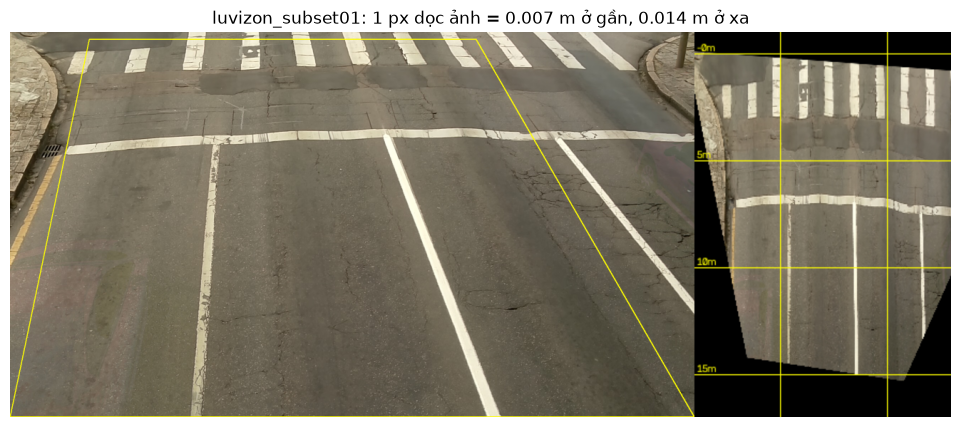

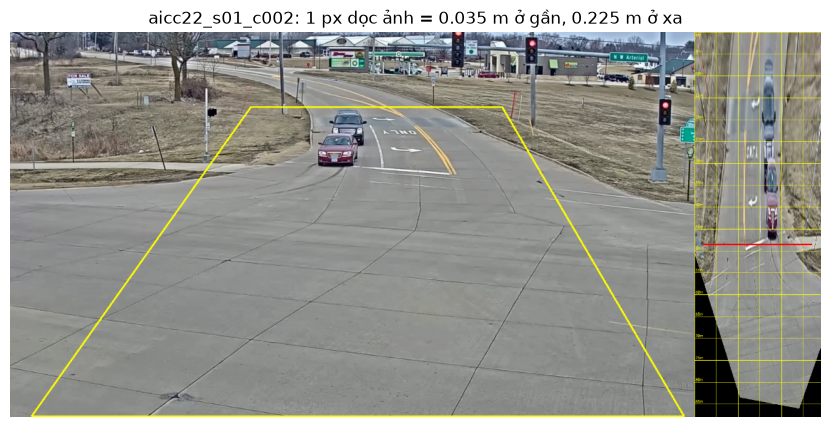

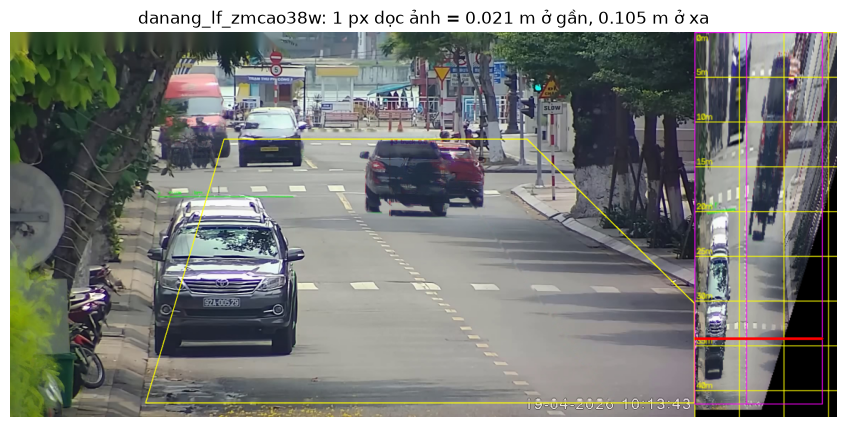

In [2]:
cams = {"luvizon_subset01": "luvizon_bg.jpg", "aicc22_s01_c002": "aicc22_bg.jpg", "danang_lf_zmcao38w": "danang_bg.jpg"}
for cam, bg in cams.items():
    cal = Calibration.from_yaml(ROOT / f"configs/cameras/{cam}.yaml")
    sheet = calibration_sheet(cv2.imread(str(OUT / "calib" / bg)), cal, OUT / "calib" / f"{cam}_sheet.jpg", height=540)
    plt.figure(figsize=(15, 5)); plt.imshow(cv2.cvtColor(sheet, cv2.COLOR_BGR2RGB)); plt.axis("off")
    plt.title(f"{cam}: 1 px dọc ảnh = {cal.metres_per_pixel(cal.image_size[0]/2, cal.image_size[1]*0.9):.3f} m ở gần, "
              f"{cal.metres_per_pixel(cal.image_size[0]/2, cal.image_size[1]*0.35):.3f} m ở xa"); plt.show()

## 2. Tốc độ trên Luvizon (GT cảm biến vòng từ)
Mỗi xe trong `vehicles.xml` có tốc độ đo bằng vòng từ, vị trí biển số tại frame `iframe` và làn.
Ghép xe GT với track có box chứa tâm biển số tại `iframe`, rồi đo tốc độ track bằng hồi quy vị trí theo thời gian trên các điểm chạm đất hợp lệ
trong 2 s sau `iframe`.

Hình học: homography chỉnh thẳng mặt đường đi kèm bộ dữ liệu (`matrix.txt`) và **một** hệ số mét/đơn vị.
Hệ số này lấy từ video01 (trung vị tỉ số GT/dự đoán), sau đó cố định và **kiểm tra trên video02**.
"Within −3/+2" là tỉ lệ xe có sai số trong khoảng [−3, +2] km/h, khoảng sai số mà bài báo Luvizon dùng để đánh giá.

In [3]:
scale = json.loads((OUT / "luvizon/scale.json").read_text()); print({k: scale[k] for k in ("s_fit_m_per_unit", "implied_lane_width_m", "n_fit")})
lz = pd.concat([pd.read_csv(p) for p in sorted((OUT / "luvizon").glob("speed_eval*.csv"))])
lz["model"] = lz["tracks"].str.replace("_bytetrack_vn", "")
lz["geometry"] = lz["geometry"].str.replace(r" \(s=.*\)", "", regex=True)
lz[["video", "split", "model", "geometry", "gt_vehicles", "measured", "coverage_%", "MAE_kmh", "RMSE_kmh", "bias_kmh", "within_-3_+2_%"]].round(2)

{'s_fit_m_per_unit': 0.01664195421469861, 'implied_lane_width_m': 3.132212746621922, 'n_fit': 65}


,video,split,model,geometry,gt_vehicles,measured,coverage_%,MAE_kmh,RMSE_kmh,bias_kmh,within_-3_+2_%
0,v01,fit (train),yolo26_vn_finetuned,old pipeline (default trapezoid),110,17,15.46,98.53,104.67,98.53,0.00
1,v01,fit (train),yolo26_vn_finetuned,dataset H + lane width 3.5 m,110,65,59.09,5.04,5.56,4.81,20.00
2,v01,fit (train),yolo26_vn_finetuned,dataset H + factor fitted on v01,110,65,59.09,1.01,1.44,-0.26,92.31
3,v02,test,yolo26_vn_finetuned,old pipeline (default trapezoid),280,48,17.14,106.90,116.56,106.90,0.00
4,v02,test,yolo26_vn_finetuned,dataset H + lane width 3.5 m,280,177,63.21,5.29,5.68,4.71,13.56
5,v02,test,yolo26_vn_finetuned,dataset H + factor fitted on v01,280,177,63.21,1.19,1.92,-0.45,88.70
0,v01,fit (train),yolo26s,old pipeline (default trapezoid),110,26,23.64,110.51,116.74,110.51,0.00
1,v01,fit (train),yolo26s,dataset H + lane width 3.5 m,110,94,85.46,5.03,5.55,4.84,18.08
2,v01,fit (train),yolo26s,dataset H + factor fitted on v01,110,94,85.46,1.12,1.49,-0.28,89.36
3,v02,test,yolo26s,old pipeline (default trapezoid),280,47,16.79,100.64,111.15,100.64,0.00


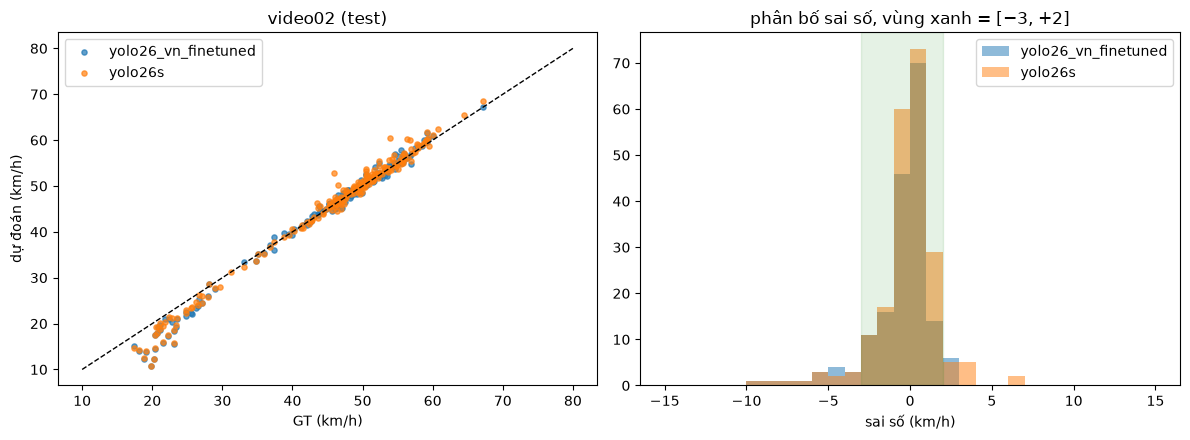

In [4]:
pv = pd.concat([pd.read_csv(p).assign(src=p.stem) for p in sorted((OUT / "luvizon").glob("per_vehicle*.csv"))])
pv = pv[pv.geometry.str.contains("fitted") & (pv.video == "v02") & (pv.n_points >= 5)]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, g in pv.groupby("src"):
    lab = name.replace("per_vehicle_", "")
    ax[0].scatter(g.gt_kmh, g.pred_kmh, s=14, alpha=.7, label=lab)
    ax[1].hist((g.pred_kmh - g.gt_kmh).clip(-15, 15), bins=np.arange(-15, 15.5, 1), alpha=.5, label=lab)
lim = [10, 80]; ax[0].plot(lim, lim, "k--", lw=1); ax[0].set_xlabel("GT (km/h)"); ax[0].set_ylabel("dự đoán (km/h)"); ax[0].legend(); ax[0].set_title("video02 (test)")
ax[1].axvspan(-3, 2, color="g", alpha=.1); ax[1].set_xlabel("sai số (km/h)"); ax[1].legend(); ax[1].set_title("phân bố sai số, vùng xanh = [−3, +2]")
plt.tight_layout(); plt.savefig(OUT / "luvizon/v02_scatter.png", dpi=110); plt.show()

## 3. AICC22-Custom: tách sai số hình học và sai số detector
Tốc độ tham chiếu = khung GT (người gán) chiếu bằng hiệu chuẩn GPS của AI City.

In [5]:
print(json.loads((OUT / "aicc22/summary.json").read_text()))
pd.read_csv(OUT / "aicc22/speed_eval.csv")

{'gt_frame_offset': -1, 'reference_vehicles': 13, 'reference_speed_median_kmh': 32.80444145659808, 'gt_counted_stop_bar': 1, 'reference_moving_mean_kmh': 28.61332388215328, 'old_geometry_moving_mean_kmh': 14.803903211490985}


,what,vehicles,matched,MAE_kmh,RMSE_kmh,bias_kmh,MAPE_%,counted,tracks
0,"GT boxes, old trapezoid geometry",13,13,10.15,14.83,-10.15,32.29,NaN,NaN
1,"finetuned tracks, AIC geometry",13,11,2.87,4.80,2.13,17.62,1.0,30.0
2,"finetuned tracks, old geometry (old pipeline)",13,11,11.14,16.04,-10.57,32.34,NaN,NaN
3,"coco tracks, AIC geometry",13,13,2.21,5.73,1.27,18.72,1.0,23.0
4,"coco tracks, old geometry (old pipeline)",13,13,9.94,14.76,-9.94,29.67,NaN,NaN


## 4. Tracking trên VNTraffic
Offset frame của GT được ước lượng bằng IoU (VNTraffic đánh số từ 0). Hàng "old loader" là cách đọc cũ (frame − 1), giữ lại để so sánh.
HOTA~ là bản rút gọn (ghép Hungarian theo từng frame), không phải TrackEval chính thức.

In [6]:
print(pd.read_csv(OUT / "mot/gt_frame_offset.csv").to_string(index=False))
pd.read_csv(OUT / "mot/mot_vntraffic.csv")

 offset  mean_best_iou
     -3       0.468792
     -2       0.496335
     -1       0.522617
      0       0.541424
      1       0.530220
      2       0.505967
      3       0.479816


,tracker,MOTA,IDF1,HOTA~,IDSW,FP,FN,MT,GT_ids,gt_reading,proc_fps_cpu
0,bytetrack_vn,0.5768,0.6973,0.5302,23,1723,5040,40,85,GT offset +0 (estimated),2.54
1,bytetrack_vn,0.5124,0.6636,0.5112,24,2239,5556,27,85,GT offset -1 (old loader),2.54
2,botsort_vn,0.5947,0.7078,0.5506,21,1634,4844,42,85,GT offset +0 (estimated),2.42
3,botsort_vn,0.5286,0.6734,0.5281,21,2164,5374,29,85,GT offset -1 (old loader),2.42


## 5. CCTV Đà Nẵng
Dùng tracks đã chạy trên Colab (YOLO26 fine-tune + ByteTrack, 900 frame mỗi đoạn). Tốc độ ở camera này là ước lượng
(hiệu chuẩn từ điểm tụ, xem `configs/cameras/danang_lf_zmcao38w.yaml`).

In [7]:
cal = Calibration.from_yaml(ROOT / "configs/cameras/danang_lf_zmcao38w.yaml")
rows, cong = [], None
for i in (1, 2, 3):
    recs = [json.loads(l) for l in open(OUT / f"tracks/tracks_danang_cam_0{i}.jsonl")]
    r = analyse(recs, cal)
    rows.append(r["summary"] | {"camera_id": f"danang_cam_0{i}"})
    cong = r["congestion"] if cong is None else cong + r["congestion"]
pd.DataFrame(rows).set_index("camera_id").T

camera_id,danang_cam_01,danang_cam_02,danang_cam_03
frames,900,900,900
records,3828,2744,4179
tracks,104,52,144
tracks_in_zone,82,36,107
tracks_moved_5m,6,1,8
edge_boxes,893,1046,1036
counted,4,1,9
counts_by_tripwire,{'towards': 4},{'away': 1},"{'away': 3, 'towards': 6}"
counts_by_class,{'motorbike': 4},{'bus': 1},"{'truck': 5, 'bus': 2, 'car': 1, 'motorbike': 1}"
speed_moving_mean_kmh,10.139339,9.007837,13.274728


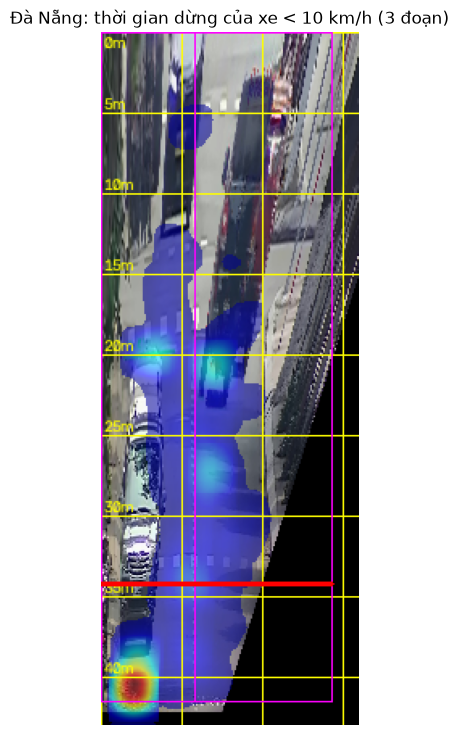

In [8]:
bev = cal.warp_bev(cv2.imread(str(OUT / "calib/danang_bg.jpg")))
heat = cv2.applyColorMap(np.uint8(255 * cong / cong.max()), cv2.COLORMAP_JET); m = cong > 0.02 * cong.max()
bev[m] = cv2.addWeighted(bev, .45, heat, .55, 0)[m]
plt.figure(figsize=(4, 9)); plt.imshow(cv2.cvtColor(draw_bev_grid(bev, cal), cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title("Đà Nẵng: thời gian dừng của xe < 10 km/h (3 đoạn)"); plt.savefig(OUT / "calib/danang_congestion.jpg", dpi=110, bbox_inches="tight"); plt.show()

Số xe được đếm và số track đi được hơn 5 m trong vùng đo rất ít so với lượng xe thấy trong video: detector bỏ sót phần lớn ô tô
(xe con bị gán "truck"/"bus") và track bị vỡ (trung vị 6–8 frame). Hình học không phải nguyên nhân chính ở camera này;
cần chạy lại tracking với detector tốt hơn trên video gốc.